In [2]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import pickle
import matplotlib.font_manager as fm
font_path = '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Times New Roman'

def load_pkl(file_path):
    with open(file_path, 'rb') as f:
        return pickle.load(f)

In [3]:
ind_cell_df = pd.read_csv('cell_positions_h01_rotated_full.csv')
ind_cell_df.rename({'Unnamed: 0': 'id_new'}, axis=1, inplace=True)

In [4]:
ind_cell_df[['x_new', 'y_new', 'z_new', 'layer']].to_csv('xyz_layer.csv')

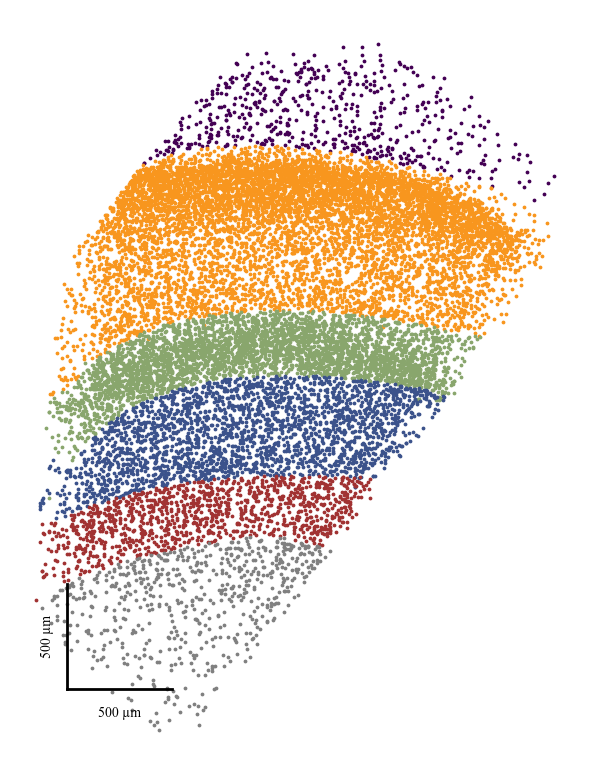

In [5]:
import matplotlib.pyplot as plt
df = ind_cell_df
# Keep only needed columns
df = df[["x_new", "y_new", "z_new", "layer"]].dropna().copy() 

layer_colors = {
    1: "#440154",
    2: "#f8961e",
    3: "#f8961e",
    4: "#89A66D",
    5: "#3b528b",
    6: "#A13232",
    7: "gray",
}

fig, ax = plt.subplots(figsize=(6, 8))

# --------------------------------------------------
# Plot neurons
# --------------------------------------------------

for layer, data in df.groupby("layer"):

    ax.scatter(
        data["x_new"],
        data["y_new"],
        s=3,
        color=layer_colors[layer],
        label=layer,
        rasterized=True,     # only the points become raster
    )

# Preserve real spatial proportions
ax.set_aspect("equal")


# --------------------------------------------------
# Scale bars
# --------------------------------------------------

scale_x = 500   # µm
scale_y = 500   # µm

# Data limits
xmin, xmax = df["x_new"].min(), df["x_new"].max()
ymin, ymax = df["y_new"].min(), df["y_new"].max()

dx = xmax - xmin
dy = ymax - ymin

# Position of scale-bar corner
x0 = xmin + 0.06 * dx
y0 = ymin + 0.06 * dy

# Horizontal scale bar
ax.plot(
    [x0, x0 + scale_x],
    [y0, y0],
    color="black",
    lw=2
)

ax.text(
    x0 + scale_x / 2,
    y0 - 0.025 * dy,
    f"{scale_x} µm",
    ha="center",
    va="top",
    fontsize=10
)

# Vertical scale bar
ax.plot(
    [x0, x0],
    [y0, y0 + scale_y],
    color="black",
    lw=2
)

ax.text(
    x0 - 0.025 * dx,
    y0 + scale_y / 2,
    f"{scale_y} µm",
    ha="right",
    va="center",
    rotation=90,
    fontsize=10
)


# --------------------------------------------------
# Remove normal axes
# --------------------------------------------------

ax.axis("off")

plt.tight_layout()

plt.savefig(
    "H01_neuron_positions_xy.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.show()

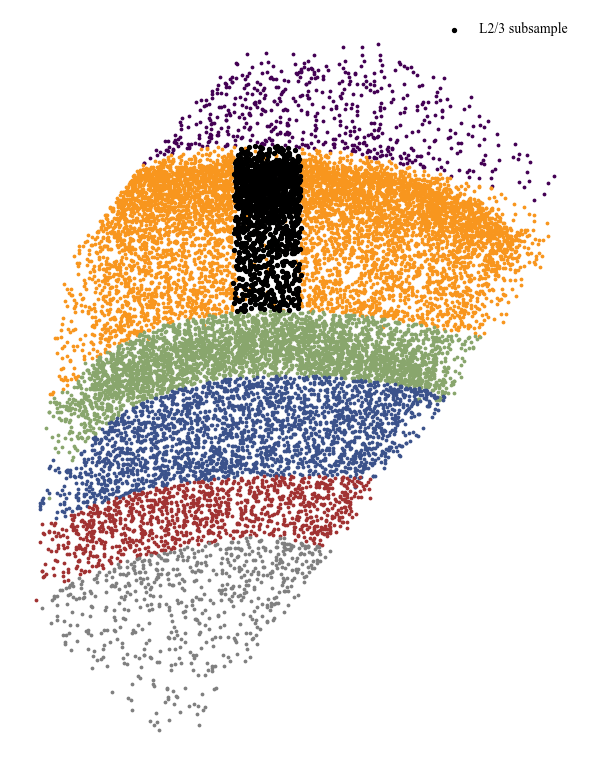

In [6]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# Main dataframe and subsample
# --------------------------------------------------
df = ind_cell_df.copy()

ind_cell_df_sub = df[
    (df['distance2Dcenter'] <= 160.98) &
    (df['z_new'] >= 4.0) &
    (df['z_new'] <= 170.0) &
    (df['layer'] >= 2) &
    (df['layer'] <= 3)
]

layer_colors = {
    1: "#440154",
    2: "#f8961e",
    3: "#f8961e",
    4: "#89A66D",
    5: "#3b528b",
    6: "#A13232",
    7: "gray",
}

fig, ax = plt.subplots(figsize=(6, 8))

# --------------------------------------------------
# Plot all cells
# --------------------------------------------------
for layer, data in df.groupby("layer"):
    ax.scatter(
        data["x_new"],
        data["y_new"],
        s=3,
        color=layer_colors.get(layer, "gray"),
        rasterized=True
    )

# --------------------------------------------------
# Overlay subsample
# --------------------------------------------------
ax.scatter(
    ind_cell_df_sub["x_new"],
    ind_cell_df_sub["y_new"],
    s=8,
    color="black",
    alpha=1.0,
    label="L2/3 subsample",
    rasterized=True
)

ax.set_aspect("equal")
ax.axis("off")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("H01_neuron_positions_xy_subsample.pdf", dpi=600, bbox_inches="tight")
plt.show()

# L23 NN 1250

In [8]:
ind_cell_df = pd.read_csv('cell_positions_h01_rotated_full.csv')
ind_cell_df.rename({'Unnamed: 0': 'id_new'}, axis=1, inplace=True)

ind_cell_df_sub = ind_cell_df[(ind_cell_df['distance2Dcenter'] <= 160.98) & (ind_cell_df['z_new'] >= 4.0) & (ind_cell_df['z_new'] <= 170.0) & (ind_cell_df['layer'] >= 2) & (ind_cell_df['layer'] <= 3)]
#ind_cell_df_sub = ind_cell_df[(ind_cell_df['layer'] == 2) | (ind_cell_df['layer'] == 3)]
ind_cell_df_sub = ind_cell_df_sub.sort_values(by='layer')
ind_cell_df_sub = ind_cell_df_sub.sort_values(by='z_new') 
ind_cell_df_sub = ind_cell_df_sub.sort_values(by='EI')
ind_cell_df_sub = ind_cell_df_sub.reset_index(drop=True) 
print(f"Ntotal = {len(ind_cell_df_sub)}, N exc = {len(ind_cell_df_sub[ind_cell_df_sub['EI'] == 'excitatory'])}, N inh = {len(ind_cell_df_sub[ind_cell_df_sub['EI'] == 'inhibitory'])}")
print(f"Fraction exc = {(len(ind_cell_df_sub[ind_cell_df_sub['EI'] == 'excitatory']) / len(ind_cell_df_sub))*100}%, Fraction inh = {(len(ind_cell_df_sub[ind_cell_df_sub['EI'] == 'inhibitory']) / len(ind_cell_df_sub))*100}%")
ind_cell_df = ind_cell_df_sub
edges_pre_post = np.loadtxt('edges_pre_post.txt')
print('Edges loaded')

N_inh = len(ind_cell_df_sub[ind_cell_df_sub['EI'] == 'inhibitory'])

frac_sst = 0.25
frac_pv = 0.35
frac_vip = 0.4

N_sst = int(round(frac_sst * N_inh))
N_pv = int(round(frac_pv * N_inh))
N_vip = N_inh - N_sst - N_pv

ind_cell_df_sub.loc[ind_cell_df_sub['EI'] == 'excitatory', 'type'] = 'PYR'
ind_cell_df_sub.loc[ind_cell_df_sub['EI'] == 'inhibitory', 'type'] = 'VIP'

# Get indices of the VIP rows
vip_idx = ind_cell_df_sub.index[ind_cell_df_sub["type"] == "VIP"].to_numpy()

# Check that there are enough VIP cells
assert len(vip_idx) >= N_sst + N_pv + N_vip, "Not enough VIP elements"

# Reproducible random generator
SEED = 1223
rng = np.random.default_rng(SEED)

# Shuffle inhibitory-cell identities
rng.shuffle(vip_idx)

# Assign the new types
start = 0
ind_cell_df_sub.loc[vip_idx[start:start + N_sst], "type"] = "SST"
start += N_sst
ind_cell_df_sub.loc[vip_idx[start:start + N_pv], "type"] = "PV"
start += N_pv
ind_cell_df_sub.loc[vip_idx[start:start + N_vip], "type"] = "VIP"

pop_order = ["PYR", "SST", "PV", "VIP"]

ind_cell_df_sub["type"] = pd.Categorical(
    ind_cell_df_sub["type"],
    categories=pop_order,
    ordered=True
)

ind_cell_df_sub = (
    ind_cell_df_sub
    .sort_values(["type"])
    .reset_index(drop=True)
)


ind_cell_df = ind_cell_df_sub.copy()
N_population = ind_cell_df_sub['type'].value_counts()
print(N_population)

Ntotal = 1250, N exc = 800, N inh = 450
Fraction exc = 64.0%, Fraction inh = 36.0%
Edges loaded
PYR    800
VIP    180
PV     158
SST    112
Name: type, dtype: int64


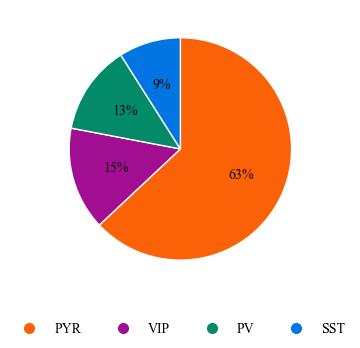

In [11]:
import matplotlib.pyplot as plt

type_colors = {
    "PYR": "#fb6106",
    "VIP": "#a10e91",
    "PV":  "#038b69",
    "SST": "#0375e3",
}

# Example: three different population compositions
populations = {
    "Condition 1": {"PYR": 63, "VIP": 15, "PV": 13, "SST": 9}}

fig, axes = plt.subplots(1, 1, figsize=(10, 3.5))


data = populations["Condition 1"]
labels = list(data.keys())
values = list(data.values())
colors = [type_colors[x] for x in labels]

plt.pie(
    values,
    colors=colors,
    startangle=90,
    counterclock=False,
    autopct="%1.0f%%",
    wedgeprops={"edgecolor": "white", "linewidth": 1},
)

# One common legend
handles = [
    plt.Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=type_colors[x],
        markersize=9,
        label=x
    )
    for x in type_colors
]

fig.legend(
    handles=handles,
    labels=type_colors.keys(),
    loc="lower center",
    ncol=4,
    frameon=False,
)

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.savefig('Proportion.pdf', format = 'pdf')
plt.show()

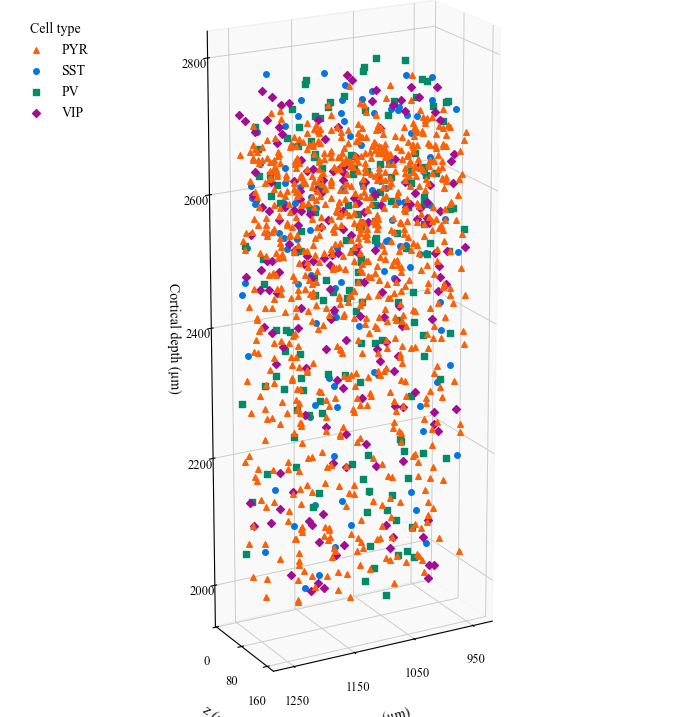

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Data
# --------------------------------------------------
df = ind_cell_df_sub[["x_new", "y_new", "z_new", "type"]].dropna().copy()

# --------------------------------------------------
# Colors and markers
# --------------------------------------------------
type_colors = {
    "PYR": "#fb6106",
    "VIP": "#a10e91",
    "PV":  "#038b69",
    "SST": "#0375e3",
}

type_markers = {
    "PYR": "^",   # triangle
    "SST": "o",   # circle
    "PV":  "s",   # square
    "VIP": "D",   # diamond
}

type_order = ["PYR", "SST", "PV", "VIP"]

# --------------------------------------------------
# Camera converted from Plotly
# --------------------------------------------------
elev = 19.2
azim = 60.9
roll = 0

# If you want a bit more rotation toward y, try:
# azim = 65
# or
# azim = 70

# --------------------------------------------------
# Figure
# --------------------------------------------------
fig = plt.figure(figsize=(7, 9))
ax = fig.add_subplot(111, projection="3d")

for cell_type in type_order:
    data = df[df["type"] == cell_type]

    ax.scatter(
        data["x_new"],
        data["z_new"],
        data["y_new"],
        s=16,
        color=type_colors[cell_type],
        marker=type_markers[cell_type],
        label=cell_type,
        depthshade=False,
        rasterized=True
    )

# --------------------------------------------------
# Preserve spatial proportions
# --------------------------------------------------
ax.set_box_aspect((
    np.ptp(df["x_new"]),
    np.ptp(df["z_new"]),
    np.ptp(df["y_new"])
))

# --------------------------------------------------
# View / projection
# --------------------------------------------------
ax.view_init(elev=elev, azim=azim, roll=roll)
ax.set_proj_type("persp")

# --------------------------------------------------
# Labels
# --------------------------------------------------
ax.set_xlabel("x (µm)", labelpad=8)
ax.set_zlabel("Cortical depth (µm)", labelpad=12)
ax.set_ylabel("z (µm)", labelpad=8)

# --------------------------------------------------
# Manual ticks
# Adjust if you want fewer/more
# --------------------------------------------------
ax.set_xticks([950, 1050, 1150, 1250])
ax.set_zticks([2000, 2200, 2400, 2600, 2800])
ax.set_yticks([0, 80, 160])

ax.tick_params(axis='x', labelsize=9)
ax.tick_params(axis='y', labelsize=9)
ax.tick_params(axis='z', labelsize=9)

# --------------------------------------------------
# Keep grid, but make it subtle
# --------------------------------------------------
ax.grid(True)

# Light pane colors to keep the 3D look
ax.xaxis.pane.set_facecolor((0.96, 0.96, 0.96, 1.0))
ax.yaxis.pane.set_facecolor((0.96, 0.96, 0.96, 1.0))
ax.zaxis.pane.set_facecolor((0.96, 0.96, 0.96, 1.0))

# Light grid lines
for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis._axinfo["grid"]["color"] = (0.80, 0.80, 0.80, 1.0)
    axis._axinfo["grid"]["linewidth"] = 0.7
    axis._axinfo["grid"]["linestyle"] = "-"


# --------------------------------------------------
# Legend
# --------------------------------------------------
ax.legend(
    title="Cell type",
    frameon=False,
    loc="upper left"
)

plt.tight_layout()

## Uncomment to save
plt.savefig(
    "H01_L23_subsample_3D_matplotlib.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.show()

In [13]:
List_cell_df = set(ind_cell_df_sub["id"].values)

index_pre_post_ = []
index_pre_post_unique = []

for a, b in edges_pre_post:

    if a in List_cell_df and b in List_cell_df and str(a)+'->'+str(b) not in index_pre_post_unique:

        index_pre_post_unique.append(str(a)+'->'+str(b))

        pre_index = ind_cell_df.index[ind_cell_df["id"] == a][0]
        post_index = ind_cell_df.index[ind_cell_df["id"] == b][0]

        mtype_pre = ind_cell_df.loc[pre_index, "type"]
        mtype_post = ind_cell_df.loc[post_index, "type"]

        x_pre = ind_cell_df.loc[pre_index, "x_new"]
        y_pre = ind_cell_df.loc[pre_index, "y_new"]
        z_pre = ind_cell_df.loc[pre_index, "z_new"]

        x_post = ind_cell_df.loc[post_index, "x_new"]
        y_post = ind_cell_df.loc[post_index, "y_new"]
        z_post = ind_cell_df.loc[post_index, "z_new"]

        distance = np.sqrt(
            (x_pre - x_post)**2 +
            (y_pre - y_post)**2 +
            (z_pre - z_post)**2
        )

        population_conn = mtype_pre + "->" + mtype_post
        
        type_pre = ind_cell_df.loc[pre_index, "EI"]
        type_post = ind_cell_df.loc[post_index, "EI"]
        general_conn = ind_cell_df.loc[pre_index, 'EI'] + "->" + ind_cell_df.loc[post_index, 'EI']

        index_pre_post_.append([pre_index,post_index,mtype_pre,mtype_post,population_conn,distance, general_conn, type_pre, type_post, int(a), int(b)])

index_pre_post_unique = pd.DataFrame(index_pre_post_, columns=["pre", "post", "mtype pre", "mtype post", "population conn", "distance", 'General conn', 'type pre', 'type post', "id_pre", "id_post"])


In [14]:
Kout = []

aa, bb = np.unique([index_pre_post_unique["id_pre"].values], return_counts=True)

for i,id in enumerate(ind_cell_df_sub["id"].values):
    for ii,id2 in enumerate(aa):
        if id == id2:
            Kout.append(bb[ii])
    if len(Kout) == i:
        Kout.append(0)

    # print(i,Kout[i])
ind_cell_df_sub["Kout"] = Kout
ind_cell_df_sub

,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info,Kout
0,7290,1844456976,2744296,915320,7680,1074.567462,2479.214655,7.680,80.875039,2,excitatory,L23E,PYR,1988,612,2600,L2pyramidalneuron,0
1,6217,3459869102,2543344,1240496,34560,1178.907400,2111.472470,34.560,93.357384,3,excitatory,L23E,PYR,5420,1494,6914,L3pyramidalneuron,1
2,5716,3692039324,2490168,997024,159189,963.354579,2236.545582,159.189,155.748427,3,excitatory,L23E,PYR,4072,966,5038,L3pyramidalneuron,0
3,4269,29138311875,2825496,949872,159189,1154.864378,2515.816375,159.189,92.713007,2,excitatory,L23E,PYR,1304,337,1641,L2pyramidalneuron,5
4,6907,2396871483,2750672,798072,159189,992.349492,2563.047539,159.189,131.050500,2,excitatory,L23E,PYR,2817,842,3659,L2pyramidalneuron,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1245,11147,37262192364,2939616,729344,95829,1069.146671,2748.858105,95.829,32.884060,2,inhibitory,L23I,VIP,368,242,610,L2neuroninterneuron,0
1246,11007,37466284408,2943960,904144,95829,1201.068735,2634.095396,95.829,101.707043,2,inhibitory,L23I,VIP,1081,521,1602,L2neuroninterneuron,2
1247,10718,47217430022,2519368,977664,154965,968.774600,2271.158773,154.965,148.970373,3,inhibitory,L23I,VIP,248,145,393,L3neuroninterneuron,0
1248,14637,29372250446,2929736,955200,53760,1229.145126,2589.142603,53.760,132.742117,2,inhibitory,L23I,VIP,17,32,49,L2neuroninterneuron,0


In [15]:
index_pre_post = index_pre_post_unique
aux = index_pre_post['population conn'].value_counts()
conn_prob = {'pre':[], 'post':[], 'prob':[], 'TOTAL':[]}
for connection in aux.keys():
    pre, post = connection.split('->')
    conn_prob['pre'].append(pre)
    conn_prob['post'].append(post)
    conn_prob['prob'].append(aux[connection] / ((N_population[pre]-1) * N_population[post]))
    conn_prob['TOTAL'].append(aux[connection])

conn_prob = pd.DataFrame(conn_prob)

In [18]:
conn_prob

,pre,post,prob,TOTAL
0,PYR,PYR,0.002750,1758
1,PYR,VIP,0.003595,517
2,PYR,PV,0.003953,499
3,PYR,SST,0.003721,333
4,PV,PYR,0.001457,183
5,VIP,PYR,0.000992,142
6,SST,PYR,0.001306,116
7,VIP,PV,0.000919,26
8,PV,VIP,0.000885,25
9,VIP,VIP,0.000745,24


# Increase the number of connections using the FIT from full h01 Network

In [24]:
def exponential_model(d, A, lamb):
    return A * np.exp(-d / lamb)

def gaussian_model(d, A, sigma):
    return A * np.exp(-(d**2) / (2 * sigma**2))

distance_rules = pd.read_excel('distance_probability_fits_PYR_SST_VIP_PV.xlsx')
distance_rules.head()

,population conn,Best fit,Exp A,Exp lambda (um),Exp R2,Gauss A,Gauss sigma (um),Gauss R2
0,PYR->PYR,Exp.,0.010100,103.578376,0.999574,0.007589,97.876964,0.980571
1,PYR->SST,Exp.,0.029204,73.767138,0.999785,0.021161,72.594428,0.986542
2,PYR->VIP,Gauss.,0.024346,85.302465,0.993468,0.018108,82.289986,0.994523
3,PYR->PV,Gauss.,0.019639,98.472079,0.982735,0.014914,93.468421,0.995966
4,SST->PYR,Exp.,0.009371,90.502753,0.994764,0.006991,87.174134,0.993747


In [25]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist


etayHay_Nconns = {
'PYR->PYR':96193,
'PYR->SST':7672,
'PYR->PV':5038,
'PYR->VIP':5719,
'SST->PYR':7619,
'SST->SST':105,
'SST->PV':687,
'SST->VIP':221,
'PV->PYR':5354,
'PV->SST':195,
'PV->PV':1773,
'PV->VIP':180,
'VIP->PYR':0,
'VIP->SST':1428,
'VIP->PV':546,
'VIP->VIP':328,
}

h01_conn = index_pre_post_unique['population conn'].value_counts()

augmentation_factors = {
key : etayHay_Nconns[key] / h01_conn[key]
for key in h01_conn.keys()
}


# --------------------------------------------------
# Augmentation factors for each population pair
# --------------------------------------------------

augmentation_factors = {
key : etayHay_Nconns[key] / h01_conn[key]
for key in h01_conn.keys()
}

index_pre_post = index_pre_post_unique
# --------------------------------------------------
# Get original number of connections per population pair
# --------------------------------------------------

Cij = index_pre_post["population conn"].value_counts()

# --------------------------------------------------
# Store all new connections here
# --------------------------------------------------

all_new_connections = []

# --------------------------------------------------
# Loop over all population pairs in distance_rules
# --------------------------------------------------

keys_conn = distance_rules["population conn"].unique()

for pop_conn in keys_conn:

    # --------------------------------------------------
    # Check whether augmentation factor exists
    # --------------------------------------------------

    if pop_conn not in augmentation_factors:
        print(
            f"Skipping {pop_conn}: "
            f"no augmentation factor specified."
        )
        continue

    # --------------------------------------------------
    # Skip if this population pair does not exist
    # in the original network
    # --------------------------------------------------

    if pop_conn not in Cij.index:
        print(
            f"Skipping {pop_conn}: "
            f"not found in original connections."
        )
        continue

    # --------------------------------------------------
    # Get augmentation factor for this population pair
    # --------------------------------------------------

    s = float(augmentation_factors[pop_conn])

    # --------------------------------------------------
    # Extract one row from distance_rules
    # --------------------------------------------------

    rule_row = distance_rules[
        distance_rules["population conn"] == pop_conn
    ].iloc[0]

    best_fit = rule_row["Best fit"]
    

    # --------------------------------------------------
    # Get lambda or sigma depending on the best fit
    # --------------------------------------------------

    if best_fit == "Exp.":
        A = float(rule_row["Exp A"])
        lamb = float(rule_row["Exp lambda (um)"])
        sigma = None

    elif best_fit == "Gauss.":
        A = float(rule_row["Gauss A"])
        sigma = float(rule_row["Gauss sigma (um)"])
        lamb = None

    else:

        print(
            f"Skipping {pop_conn}: "
            f"unknown fit type {best_fit}."
        )
        continue

    # --------------------------------------------------
    # Number of new connections to add
    # --------------------------------------------------

    Cij_original = Cij[pop_conn]

    Cij_add = int(round((s - 1) * Cij_original))

    if Cij_add <= 0:
        print(
            f"Skipping {pop_conn}: "
            f"Cij_add <= 0."
        )
        continue

    # --------------------------------------------------
    # Split population pair
    # --------------------------------------------------

    pre, post = pop_conn.split("->")

    # --------------------------------------------------
    # Select neurons from each population
    # --------------------------------------------------

    pop_pre = ind_cell_df[
        ind_cell_df["type"] == pre
    ].copy()

    pop_post = ind_cell_df[
        ind_cell_df["type"] == post
    ].copy()

    pre_indices = pop_pre.index.values
    post_indices = pop_post.index.values

    if len(pre_indices) == 0 or len(post_indices) == 0:

        print(
            f"Skipping {pop_conn}: "
            f"empty pre or post population."
        )
        continue

    pre_pos = pop_pre[
        ["x_new", "y_new", "z_new"]
    ].values.astype(float)

    post_pos = pop_post[
        ["x_new", "y_new", "z_new"]
    ].values.astype(float)

    # --------------------------------------------------
    # Compute all pairwise distances
    # --------------------------------------------------

    D = cdist(pre_pos, post_pos)

    # --------------------------------------------------
    # Create all possible candidate pre-post pairs
    # --------------------------------------------------

    pre_grid, post_grid = np.meshgrid(
        pre_indices,
        post_indices,
        indexing="ij"
    )

    candidate_pre = pre_grid.ravel()
    candidate_post = post_grid.ravel()
    candidate_dist = D.ravel()

    # --------------------------------------------------
    # Remove only autapses
    # Repeated pre-post pairs are still allowed
    # --------------------------------------------------

    if pre == post:

        mask_no_autapse = (
            candidate_pre != candidate_post
        )

        candidate_pre = candidate_pre[
            mask_no_autapse
        ]

        candidate_post = candidate_post[
            mask_no_autapse
        ]

        candidate_dist = candidate_dist[
            mask_no_autapse
        ]

    if len(candidate_pre) == 0:

        print(
            f"Skipping {pop_conn}: "
            f"no candidate pairs after autapse removal."
        )
        continue

    # --------------------------------------------------
    # Distance-dependent weights
    # --------------------------------------------------

    if best_fit == "Exp.":

        weights = (
            A *
            np.exp(-candidate_dist / lamb)
        )

    elif best_fit == "Gauss.":

        weights = (
            A *
            np.exp(
                -(candidate_dist ** 2)
                / (2 * sigma ** 2)
            )
        )

    # --------------------------------------------------
    # Remove invalid weights
    # --------------------------------------------------

    weights = np.asarray(
        weights,
        dtype=float
    )

    if (
        not np.all(np.isfinite(weights))
        or weights.sum() <= 0
    ):

        print(
            f"Skipping {pop_conn}: "
            f"invalid weights."
        )
        continue

    # --------------------------------------------------
    # Normalize weights
    # --------------------------------------------------

    weights = weights / weights.sum()

    # --------------------------------------------------
    # Sample new connections
    # --------------------------------------------------

    chosen = np.random.choice(
        np.arange(len(candidate_pre)),
        size=Cij_add,
        replace=True,
        p=weights
    )

    # --------------------------------------------------
    # Create dataframe with new connections
    # --------------------------------------------------

    new_connections_df = pd.DataFrame({

        "pre": candidate_pre[chosen],

        "post": candidate_post[chosen],

        "type pre": pre,

        "type post": post,

        "population conn": pop_conn,

        "distance": candidate_dist[chosen],

        "fit used": best_fit,

        "augmentation factor": s

    })

    all_new_connections.append(
        new_connections_df
    )

    # --------------------------------------------------
    # Print summary
    # --------------------------------------------------

    print(
        f"{pop_conn}: "
        f"original={Cij_original:,}, "
        f"factor={s:g}, "
        f"added={Cij_add:,}, "
        f"final={Cij_original + Cij_add:,}, "
        f"fit={best_fit}"
    )


# --------------------------------------------------
# Combine all new connections
# --------------------------------------------------

if len(all_new_connections) > 0:

    all_new_connections_df = pd.concat(
        all_new_connections,
        ignore_index=True
    )

    index_pre_post_augmented = pd.concat(
        [
            index_pre_post,
            all_new_connections_df
        ],
        ignore_index=True
    )

else:

    all_new_connections_df = pd.DataFrame()

    index_pre_post_augmented = (
        index_pre_post.copy()
    )


# --------------------------------------------------
# Summary
# --------------------------------------------------

print("----------------------------------------")
print(
    f"Original connections:  "
    f"{len(index_pre_post):,}"
)
print(
    f"Added connections:     "
    f"{len(all_new_connections_df):,}"
)
print(
    f"Augmented connections: "
    f"{len(index_pre_post_augmented):,}"
)

PYR->PYR: original=1,758, factor=54.7173, added=94,435, final=96,193, fit=Exp.
PYR->SST: original=333, factor=23.039, added=7,339, final=7,672, fit=Exp.
PYR->VIP: original=517, factor=11.0619, added=5,202, final=5,719, fit=Gauss.
PYR->PV: original=499, factor=10.0962, added=4,539, final=5,038, fit=Gauss.
SST->PYR: original=116, factor=65.681, added=7,503, final=7,619, fit=Exp.
SST->SST: original=6, factor=17.5, added=99, final=105, fit=Exp.
SST->VIP: original=12, factor=18.4167, added=209, final=221, fit=Gauss.
SST->PV: original=9, factor=76.3333, added=678, final=687, fit=Gauss.
Skipping VIP->PYR: Cij_add <= 0.
VIP->SST: original=15, factor=95.2, added=1,413, final=1,428, fit=Exp.
VIP->VIP: original=24, factor=13.6667, added=304, final=328, fit=Gauss.
VIP->PV: original=26, factor=21, added=520, final=546, fit=Exp.
PV->PYR: original=183, factor=29.2568, added=5,171, final=5,354, fit=Exp.
PV->SST: original=9, factor=21.6667, added=186, final=195, fit=Exp.
PV->VIP: original=25, factor=7.

In [26]:
index_pre_post_augmented[index_pre_post_augmented['population conn'] == 'VIP->PYR']

,pre,post,mtype pre,mtype post,population conn,distance,General conn,type pre,type post,id_pre,id_post,fit used,augmentation factor
10,1196,158,VIP,PYR,VIP->PYR,80.155348,inhibitory->excitatory,inhibitory,excitatory,1.916980e+09,1.684811e+09,NaN,NaN
40,1210,217,VIP,PYR,VIP->PYR,270.178062,inhibitory->excitatory,inhibitory,excitatory,3.813454e+10,2.774015e+09,NaN,NaN
81,1183,383,VIP,PYR,VIP->PYR,57.076964,inhibitory->excitatory,inhibitory,excitatory,2.324115e+09,2.047411e+09,NaN,NaN
111,1244,675,VIP,PYR,VIP->PYR,136.221388,inhibitory->excitatory,inhibitory,excitatory,2.947438e+10,3.066809e+09,NaN,NaN
131,1155,68,VIP,PYR,VIP->PYR,108.136552,inhibitory->excitatory,inhibitory,excitatory,2.339328e+09,1.669376e+09,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3642,1171,471,VIP,PYR,VIP->PYR,149.280505,inhibitory->excitatory,inhibitory,excitatory,3.125564e+09,1.931041e+09,NaN,NaN
3650,1197,149,VIP,PYR,VIP->PYR,146.333766,inhibitory->excitatory,inhibitory,excitatory,3.605149e+09,2.194766e+09,NaN,NaN
3655,1109,469,VIP,PYR,VIP->PYR,89.535309,inhibitory->excitatory,inhibitory,excitatory,3.797520e+10,2.528237e+09,NaN,NaN
3671,1113,597,VIP,PYR,VIP->PYR,206.328875,inhibitory->excitatory,inhibitory,excitatory,3.761140e+10,2.280852e+09,NaN,NaN


In [29]:
import plotly.graph_objects as go

# 1. Lock the X and Y to the center
center_x = ind_cell_df_sub['x_new'].mean()
center_y = ind_cell_df_sub['y_new'].mean()

# 2. Find the Z boundaries and the total Z range
z_min = ind_cell_df_sub['z_new'].min()
z_max = ind_cell_df_sub['z_new'].max()
z_range = z_max - z_min

# Define how far "out" of the points you want the top and bottom to be (e.g., 10% of the total height)
margin = z_range * 0.10

# 3. Calculate the three Z coordinates
z_upper = z_max + margin
z_middle = (z_max + z_min) / 2.0
z_bottom = z_min - margin

# Extract the final (x, y, z) tuples
point_upper = (center_x, center_y, z_upper)
point_middle = (center_x, center_y, z_middle)
point_bottom = (center_x, center_y, z_bottom)

print(f"Upper point coordinate:  {point_upper}")
print(f"Middle point coordinate: {point_middle}")
print(f"Bottom point coordinate: {point_bottom}")

Upper point coordinate:  (1103.4556874245811, 2473.7400354251436, 183.6327)
Middle point coordinate: (1103.4556874245811, 2473.7400354251436, 87.6585)
Bottom point coordinate: (1103.4556874245811, 2473.7400354251436, -8.3157)


In [30]:
ind_cell_df_sub[['x_new', 'y_new', 'z_new', 'type', 'id']].to_csv("Position_xyz_type_id_L23_NN1250.dat", sep=" ", index=False, header = False)
# ind_cell_df_sub[['type', 'x_new', 'y_new', 'z_new']].to_csv("L23_NN1254.dat", sep=",", index=True, header = True)

In [31]:
index_pre_post_augmented[["pre", "post"]].to_csv("index_pre_post_L23_PYR_SST_VIP_PV_NN1250.dat",sep=" ",index=False,header=True)

In [32]:
ind_cell_df_sub['type'].value_counts()

PYR    800
VIP    180
PV     158
SST    112
Name: type, dtype: int64

In [33]:
"""H01-anchored augmentation of a 1,250-neuron directed graph.

Run in the SAME Jupyter namespace containing:
    ind_cell_df            : indexed by 0-based position-file row / NetPyNE GID;
                             columns type, x_new, y_new, z_new
    index_pre_post_unique  : GENUINE ORIGINAL ~3,690 directed H01 edges;
                             columns pre, post; NOT the 133k-row augmented DAT
    distance_rules         : columns population conn, Best fit, Exp lambda (um),
                             Gauss sigma (um), and optionally the fitted A terms.

The output .dat has the 'pre post' header expected by fixed_network.py.
Use `%run -i h01_anchored_augmentation.py`, or paste this code into the notebook.
"""

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.special import expit
from collections import Counter

# ============================================================
# USER SETTINGS
# ============================================================
SEED = 1234
OUTPUT_PREFIX = 'H01_anchored_augmented'

# 'expected_factor': factor fixes the EXPECTED edge count, then each missing
#                    pair is sampled independently from calibrated p_ij.
# 'exact_factor':    get exactly round(factor * original_count) unique pairs;
#                    sample with weighted Gumbel-top-k (no replacement).
SELECTION_MODE = 'expected_factor'

# 0.0 = original H01 only; 0.25 = one-quarter of desired added density;
# 1.0 = full factors derived from the targets below.
AUGMENTATION_LEVEL = 1.0

# Non-fitted, phenomenological parameters. Sweep/test these against controls.
ANCHOR_SCALE_UM = 150.0      # How far from an observed (pre,post) edge to copy
ANCHOR_POWER = 0.0          # 0 = distance/degree-only; larger = stronger copying
ANCHOR_FLOOR = 0.02         # Give distant candidates a nonzero baseline score
OUT_DEGREE_POWER = 0.35     # Preserve original per-pair presynaptic preferences
IN_DEGREE_POWER = 0.35      # Preserve original per-pair postsynaptic preferences
RECIPROCAL_BONUS = 1.3      # Extra weight if j->i was in original graph

# These are your previous absolute count targets. We convert them into
# augmentation factors using counts in the GENUINE original graph.
# etayHay_Nconns = {
#     'PYR->PYR': 96193, 'PYR->SST': 7672,
#     'PYR->PV': 5038,  'PYR->VIP': 5719,
#     'SST->PYR': 7619, 'SST->SST': 105,
#     'SST->PV': 687,   'SST->VIP': 221,
#     'PV->PYR': 5354,  'PV->SST': 195,
#     'PV->PV': 1773,   'PV->VIP': 180,
#     'VIP->PYR': 0,    'VIP->SST': 1428,
#     'VIP->PV': 546,   'VIP->VIP': 328,
# }

etayHay_Nconns = {
    'PYR->PYR': 96193, 'PYR->SST': 17185,
    'PYR->PV': 11371,  'PYR->VIP': 12868,
    'SST->PYR': 17067, 'SST->SST': 533,
    'SST->PV': 3473,   'SST->VIP': 1114,
    'PV->PYR': 12085,  'PV->SST': 986,
    'PV->PV': 9106,   'PV->VIP': 914,
    'VIP->PYR': 0,    'VIP->SST': 7197,
    'VIP->PV': 2773,   'VIP->VIP': 1672,
}



# ============================================================
# VALIDATE INPUTS: original 3,690-edge graph, not augmented DAT
# ============================================================
for var_name in ('ind_cell_df', 'index_pre_post_unique', 'distance_rules'):
    if var_name not in globals():
        raise NameError(f'Missing {var_name}; load it in your notebook first.')

if SELECTION_MODE not in ('expected_factor', 'exact_factor'):
    raise ValueError('Unknown SELECTION_MODE')
if not (0.0 <= AUGMENTATION_LEVEL <= 1.0):
    raise ValueError('AUGMENTATION_LEVEL must be in [0, 1]')
if ANCHOR_SCALE_UM <= 0 or not (0 < ANCHOR_FLOOR <= 1):
    raise ValueError('Invalid anchor parameters')
if RECIPROCAL_BONUS <= 0:
    raise ValueError('RECIPROCAL_BONUS must be positive')

positions = ind_cell_df.copy()
N = len(positions)
if not positions.index.is_unique or set(positions.index) != set(range(N)):
    raise ValueError('ind_cell_df.index must be exactly 0..N-1 (file rows/GIDs).')
positions = positions.sort_index()
if 'type' not in positions:
    raise ValueError("ind_cell_df needs a 'type' column")

xyz_cols = ['x_new', 'y_new', 'z_new']
if not set(xyz_cols).issubset(positions.columns):
    xyz_cols = ['x', 'y', 'z']
if not set(xyz_cols).issubset(positions.columns):
    raise ValueError('Need either x_new/y_new/z_new or x/y/z coordinates')

xyz = positions[xyz_cols].to_numpy(dtype=float)
if not np.isfinite(xyz).all():
    raise ValueError('Coordinates contain NaN/inf')
cell_types = positions['type'].astype(str).str.replace('HL23', '', regex=False).to_numpy()
if not set(cell_types).issubset({'PYR', 'SST', 'PV', 'VIP'}):
    raise ValueError('Unknown type labels: ' + str(set(cell_types)))

base = index_pre_post_unique.copy()
if not {'pre', 'post'}.issubset(base.columns):
    raise ValueError('Original edges must have pre and post columns')
for col in ('pre', 'post'):
    values = pd.to_numeric(base[col], errors='raise').to_numpy(dtype=float)
    if not np.isfinite(values).all() or not np.equal(values, np.floor(values)).all():
        raise ValueError(f'Invalid integer GIDs in {col}')
    base[col] = values.astype(np.int64)
if ((base[['pre', 'post']] < 0) | (base[['pre', 'post']] >= N)).any().any():
    raise ValueError('A source GID is outside ind_cell_df')

n_input = len(base)
base = base.loc[base.pre != base.post].drop_duplicates(['pre', 'post']).copy()
base = base.reset_index(drop=True)
if len(base) > 10000:
    raise ValueError(
        'This looks like the AUGMENTED graph. Supply the original ~3,690 edges, '
        'NOT a deduplicated copy of the 133k-row DAT.'
    )
if len(base) != 3690:
    print(f'[WARNING] Original unique count is {len(base)}, not the expected 3,690. '
          'Verify that this is the pre-augmentation graph.')
print(f'[INPUT] {n_input} rows -> {len(base)} original, unique, non-autaptic edges')

orig_pre = base.pre.to_numpy(dtype=np.int64)
orig_post = base.post.to_numpy(dtype=np.int64)
base['type pre'] = cell_types[orig_pre]
base['type post'] = cell_types[orig_post]
base['population conn'] = base['type pre'] + '->' + base['type post']
base['distance'] = np.linalg.norm(xyz[orig_pre] - xyz[orig_post], axis=1)
base['source'] = 'H01_original'
base['fit used'] = 'original'
base['augmentation factor'] = 1.0

# Directed-pair encoding, shared with the candidate exclusion and final tests.
original_codes = np.unique(orig_pre * N + orig_post)
original_counts = base['population conn'].value_counts().to_dict()

augmentation_factors = {
    pair: 1.0 + AUGMENTATION_LEVEL * (target / original_counts[pair] - 1.0)
    for pair, target in etayHay_Nconns.items()
    if original_counts.get(pair, 0) > 0
}

# OPTIONAL: override individual factors here. Examples:
# augmentation_factors['PYR->PYR'] = 8.0
# augmentation_factors['PYR->SST'] = 4.0
# Set any factor to 1.0 to preserve that population pair unchanged.

# A disconnected original pair type has no observed H01 anchor; do not silently
# invent it, even if etayHay_Nconns specifies a positive target.
for pair, target in etayHay_Nconns.items():
    if original_counts.get(pair, 0) == 0 and target > 0:
        print(f'[WARNING] {pair}: zero ORIGINAL edges; skipping target {target}.')
    elif original_counts.get(pair, 0) > target:
        print(f'[WARNING] {pair}: original count exceeds target; original edges retained.')

rule_index = distance_rules.set_index('population conn', verify_integrity=True)
rng = np.random.default_rng(SEED)
new_parts = []
report = []

# ============================================================
# SAMPLING METHODS
# ============================================================
def sample_exact(logscore, n_new, rng):
    """Exact weighted sampling without replacement (Gumbel-top-k)."""
    if n_new == 0:
        return np.empty(0, dtype=np.int64)
    if n_new == len(logscore):
        return np.arange(len(logscore), dtype=np.int64)
    keys = logscore + rng.gumbel(size=len(logscore))
    chosen = np.argpartition(keys, -n_new)[-n_new:]
    return chosen[np.argsort(keys[chosen])[::-1]]


def sample_expected(logscore, expected_n, rng):
    """Independent Bernoulli draws with sum(p_ij) = expected_n.

    Logistic intercept calibration avoids invalid probabilities above one.
    The ACTUAL final count varies around the target.
    """
    if expected_n == 0:
        return np.empty(0, dtype=np.int64)
    if expected_n == len(logscore):
        return np.arange(len(logscore), dtype=np.int64)
    lo = -60.0 - np.max(logscore)
    hi = 60.0 - np.min(logscore)
    for _ in range(60):
        middle = (lo + hi) / 2.0
        if expit(logscore + middle).sum() < expected_n:
            lo = middle
        else:
            hi = middle
    probability = expit(logscore + (lo + hi) / 2.0)
    return np.flatnonzero(rng.random(len(logscore)) < probability)

# ============================================================
# AUGMENT ONLY MISSING PAIRS, ONE POPULATION-PAIR TYPE AT A TIME
# ============================================================
for pair, factor in augmentation_factors.items():
    n_original = original_counts[pair]
    final_target = max(n_original, int(round(n_original * factor)))
    n_new_target = final_target - n_original
    pre_type, post_type = pair.split('->')
    if n_new_target == 0:
        report.append((pair, n_original, factor, final_target, 0, n_original))
        continue

    if pair not in rule_index.index:
        raise ValueError(f'{pair}: missing distance rule')
    rule = rule_index.loc[pair]
    fit = str(rule['Best fit']).strip()

    pre_ids = np.flatnonzero(cell_types == pre_type).astype(np.int64)
    post_ids = np.flatnonzero(cell_types == post_type).astype(np.int64)
    cand_pre = np.repeat(pre_ids, len(post_ids))
    cand_post = np.tile(post_ids, len(pre_ids))

    # Remove autapses AND ALL connections present in the genuine H01 graph.
    candidate_codes = cand_pre * N + cand_post
    allowed = (cand_pre != cand_post) & ~np.isin(
        candidate_codes, original_codes, assume_unique=True
    )
    cand_pre = cand_pre[allowed]
    cand_post = cand_post[allowed]
    candidate_codes = candidate_codes[allowed]
    n_possible = len(cand_pre)
    if n_new_target > n_possible:
        raise ValueError(f'{pair}: need {n_new_target} new edges, only {n_possible} possible')
    if n_possible == 0:
        continue

    distances = np.linalg.norm(xyz[cand_pre] - xyz[cand_post], axis=1)
    if fit == 'Exp.':
        lamb = float(rule['Exp lambda (um)'])
        if not np.isfinite(lamb) or lamb <= 0:
            raise ValueError(f'{pair}: invalid exponential lambda {lamb}')
        log_distance = -distances / lamb
    elif fit == 'Gauss.':
        sigma = float(rule['Gauss sigma (um)'])
        if not np.isfinite(sigma) or sigma <= 0:
            raise ValueError(f'{pair}: invalid Gaussian sigma {sigma}')
        log_distance = -(distances ** 2) / (2.0 * sigma ** 2)
    else:
        raise ValueError(f'{pair}: unknown fit {fit!r}')

    # A is deliberately not used: under a fixed/expected density, the
    # intercept is calibrated separately and A does not change relative scores.

    # An original observed directed edge u->v serves as a template.
    # Candidate i->j scores higher when i is near u AND j is near v.
    original_group = base.loc[base['population conn'] == pair]
    obs_pre = original_group.pre.to_numpy(dtype=np.int64)
    obs_post = original_group.post.to_numpy(dtype=np.int64)
    anchor_features = np.column_stack((xyz[obs_pre], xyz[obs_post])) / ANCHOR_SCALE_UM
    candidate_features = np.column_stack((xyz[cand_pre], xyz[cand_post])) / ANCHOR_SCALE_UM
    nearest_anchor_dist, _ = cKDTree(anchor_features).query(candidate_features, k=1)
    anchor_similarity = np.exp(-0.5 * nearest_anchor_dist ** 2)
    log_anchor = ANCHOR_POWER * np.log(ANCHOR_FLOOR + anchor_similarity)

    # Retain some of the per-population-pair in-/out-degree heterogeneity.
    old_out = np.bincount(obs_pre, minlength=N)
    old_in = np.bincount(obs_post, minlength=N)
    log_degree = (OUT_DEGREE_POWER * np.log1p(old_out[cand_pre])
                  + IN_DEGREE_POWER * np.log1p(old_in[cand_post]))

    # A reverse ORIGINAL edge can also increase the score.
    reciprocal = np.isin(cand_post * N + cand_pre, original_codes, assume_unique=False)
    log_reciprocal = np.where(reciprocal, np.log(RECIPROCAL_BONUS), 0.0)

    logscore = log_distance + log_anchor + log_degree + log_reciprocal
    if not np.isfinite(logscore).all():
        raise ValueError(f'{pair}: nonfinite candidate scores')

    if SELECTION_MODE == 'exact_factor':
        selected = sample_exact(logscore, n_new_target, rng)
    else:
        selected = sample_expected(logscore, n_new_target, rng)

    added = pd.DataFrame({
        'pre': cand_pre[selected],
        'post': cand_post[selected],
        'type pre': pre_type,
        'type post': post_type,
        'population conn': pair,
        'distance': distances[selected],
        'fit used': fit,
        'augmentation factor': factor,
        'source': 'augmented',
        'anchor similarity': anchor_similarity[selected],
    })
    new_parts.append(added)
    n_actual = len(added)
    report.append((pair, n_original, factor, final_target, n_actual, n_original + n_actual))
    print(f'{pair:9s} original={n_original:6,d}, factor={factor:8.2f}, '
          f'target={final_target:7,d}, added={n_actual:7,d}, final={n_actual+n_original:7,d}')

# ============================================================
# MERGE, VERIFY, SAVE
# ============================================================
all_new_connections_df = (
    pd.concat(new_parts, ignore_index=True) if new_parts
    else pd.DataFrame(columns=['pre', 'post'])
)
index_pre_post_augmented = pd.concat(
    [base, all_new_connections_df], ignore_index=True
)

final_pre = index_pre_post_augmented.pre.to_numpy(dtype=np.int64)
final_post = index_pre_post_augmented.post.to_numpy(dtype=np.int64)
final_codes = final_pre * N + final_post
assert len(np.unique(final_codes)) == len(final_codes), 'Repeated directed connections!'
assert np.all(final_pre != final_post), 'Autapses detected!'
assert np.isin(original_codes, final_codes).all(), 'Original H01 edge was lost!'
assert np.all((final_pre >= 0) & (final_pre < N) &
              (final_post >= 0) & (final_post < N)), 'Invalid global GIDs!'

summary_df = pd.DataFrame(
    report,
    columns=['population conn', 'original', 'factor', 'target final', 'added', 'actual final']
)

# This header format is compatible with fixed_network.read_unique_edges().
# index_pre_post_augmented[['pre', 'post']].to_csv(
#     OUTPUT_PREFIX + '.dat', sep=' ', index=False
# )
# index_pre_post_augmented.to_csv(OUTPUT_PREFIX + '_annotated.csv', index=False)
# summary_df.to_csv(OUTPUT_PREFIX + '_summary.csv', index=False)

print('\n' + '-' * 60)
print(f'Original unique directed edges: {len(base):,}')
print(f'Synthetic unique directed edges: {len(all_new_connections_df):,}')
print(f'Total unique directed edges: {len(index_pre_post_augmented):,}')
print(f'Fraction of final graph observed in H01: {len(base)/len(index_pre_post_augmented):.2%}')
print('Validation: originals retained, no duplicates, no autapses, valid GIDs')
print('Output:', OUTPUT_PREFIX + '.dat')
print('Selection mode:', SELECTION_MODE)


[INPUT] 3690 rows -> 3690 original, unique, non-autaptic edges
[WARNING] VIP->PYR: original count exceeds target; original edges retained.
PYR->PYR  original= 1,758, factor=   54.72, target= 96,193, added= 94,460, final= 96,218
PYR->SST  original=   333, factor=   51.61, target= 17,185, added= 16,793, final= 17,126
PYR->PV   original=   499, factor=   22.79, target= 11,371, added= 10,816, final= 11,315
PYR->VIP  original=   517, factor=   24.89, target= 12,868, added= 12,502, final= 13,019
SST->PYR  original=   116, factor=  147.13, target= 17,067, added= 17,055, final= 17,171
SST->SST  original=     6, factor=   88.83, target=    533, added=    516, final=    522
SST->PV   original=     9, factor=  385.89, target=  3,473, added=  3,501, final=  3,510
SST->VIP  original=    12, factor=   92.83, target=  1,114, added=  1,097, final=  1,109
PV->PYR   original=   183, factor=   66.04, target= 12,085, added= 11,987, final= 12,170
PV->SST   original=     9, factor=  109.56, target=    986, 

In [34]:
index_pre_post_augmented[["pre", "post"]].to_csv("index_pre_post_L23_PYR_SST_VIP_PV_NN1250.dat",sep=" ",index=False,header=True)

In [35]:
"""Probability-based H01 augmentation, without a prescribed final edge count.

Inputs (from the user's existing Jupyter notebook):
    ind_cell_df: index 0..N-1; columns 'type' and x_new/y_new/z_new (or x/y/z)
    index_pre_post_unique: ORIGINAL (pre-augmentation) directed H01 edges, columns pre/post
    distance_rules: columns 'population conn', 'Best fit', 'Exp A',
                    'Exp lambda (um)', 'Gauss A', 'Gauss sigma (um)'.

Call:
    augmented, added, summary, bins = augment_probabilistic(
        ind_cell_df, index_pre_post_unique, distance_rules,
        fit_represents='target', anchor_power=1.5,
        output_prefix='H01_probability_augmented')

If the fitted probabilities were measured on an INCOMPLETE observed subsample,
use fit_represents='observed' and independently justify observed_fraction.
This code cannot infer observation completeness from the 3,690 observed edges.
"""
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.special import expit, logit


def _fit_probability(rule, d):
    fit = str(rule['Best fit']).strip().lower()
    if fit in ('exp.', 'exp', 'exponential'):
        a = float(rule['Exp A'])
        length = float(rule['Exp lambda (um)'])
        shape = np.exp(-d / length) if length > 0 else None
        name = 'Exp.'
    elif fit in ('gauss.', 'gauss', 'gaussian', 'gaussian.'):
        a = float(rule['Gauss A'])
        length = float(rule['Gauss sigma (um)'])
        shape = np.exp(-0.5 * (d / length)**2) if length > 0 else None
        name = 'Gauss.'
    else:
        raise ValueError(f"Unknown Best fit: {rule['Best fit']!r}")
    if not np.isfinite(a) or not (0 <= a <= 1):
        raise ValueError(f'{name} amplitude A={a}: must be a probability in [0,1], not percent.')
    if shape is None or not np.isfinite(length):
        raise ValueError(f'{name} has invalid lambda/sigma: {length}')
    return a * shape, name


def _calibrated_bernoulli(logscore, expected):
    """Independent Bernoulli probabilities with SUM(p)=expected, not exact count."""
    n = logscore.size
    if expected <= 0:
        return np.zeros(n, dtype=float)
    if expected >= n:
        return np.ones(n, dtype=float)
    lo = -80.0 - np.max(logscore)
    hi = 80.0 - np.min(logscore)
    for _ in range(55):
        mid = (lo + hi) / 2.0
        if expit(logscore + mid).sum() < expected:
            lo = mid
        else:
            hi = mid
    return expit(logscore + (lo + hi) / 2.0)


def augment_probabilistic(
    ind_cell_df,
    index_pre_post_unique,
    distance_rules,
    *,
    fit_represents='target',       # 'target' or 'observed'
    observed_fraction=None,        # REQUIRED when fit_represents='observed'; scalar or pair->fraction
    distance_bin_um=25.0,
    anchor_power=1.5,
    anchor_scale_um=150.0,
    anchor_floor=0.02,
    out_degree_power=0.0,
    in_degree_power=0.0,
    reciprocal_bonus=1.0,
    seed=1234,
    output_prefix='H01_probability_augmented',
):
    """Keep original H01 edges; independently sample missing edges using fitted p(d).

    Within each distance bin, sum(P_new) = max(0, sum(P_fit_for_ALL_pairs)-N_original).
    Anchor/degree/reciprocity scores only redistribute this expected probability
    among candidates in the SAME distance bin. Final N is random, not prescribed.
    """
    if fit_represents not in ('target', 'observed'):
        raise ValueError("fit_represents must be 'target' or 'observed'")
    if distance_bin_um <= 0 or anchor_scale_um <= 0 or anchor_floor <= 0:
        raise ValueError('Distance bin, anchor scale, and anchor floor must be positive')
    if anchor_power < 0 or out_degree_power < 0 or in_degree_power < 0 or reciprocal_bonus <= 0:
        raise ValueError('Invalid anchor/degree/reciprocity parameters')
    if fit_represents == 'observed' and observed_fraction is None:
        raise ValueError('Supply an independently justified observed_fraction for the original subsample.')

    positions = ind_cell_df.sort_index().copy()
    n = len(positions)
    if not positions.index.is_unique or not np.array_equal(positions.index.to_numpy(), np.arange(n)):
        raise ValueError('Position DataFrame must have row/GID index exactly 0..N-1.')
    poscols = ['x_new', 'y_new', 'z_new']
    if not set(poscols).issubset(positions.columns):
        poscols = ['x', 'y', 'z']
    if not set(poscols).issubset(positions.columns) or 'type' not in positions.columns:
        raise ValueError('Need columns type and x_new/y_new/z_new (or x/y/z).')
    xyz = positions[poscols].to_numpy(float)
    if not np.isfinite(xyz).all():
        raise ValueError('Nonfinite coordinates')
    types = positions['type'].astype(str).str.replace('HL23', '', regex=False).to_numpy()
    pop_order = ('PYR', 'SST', 'PV', 'VIP')
    if not set(types).issubset(set(pop_order)):
        raise ValueError(f'Unknown population names: {set(types) - set(pop_order)}')

    original = index_pre_post_unique[['pre', 'post']].copy()
    for col in ('pre', 'post'):
        vals = pd.to_numeric(original[col], errors='raise').to_numpy(float)
        if not np.isfinite(vals).all() or not np.equal(vals, np.floor(vals)).all():
            raise ValueError(f'Invalid integer GIDs in {col}')
        original[col] = vals.astype(np.int64)
    if ((original < 0) | (original >= n)).any().any():
        raise ValueError('An original pre/post index is outside position file')
    if (original.pre == original.post).any():
        raise ValueError('Original graph contains autapses; inspect them before augmentation.')
    original = original.drop_duplicates(['pre', 'post']).reset_index(drop=True)
    if len(original) > 10000:
        raise ValueError('Input looks augmented: supply the genuine original ~3,690-edge H01 graph.')
    if len(original) != 3690:
        print(f'[WARNING] Original has {len(original)} unique edges, rather than expected 3,690.')
    opre = original.pre.to_numpy(np.int64)
    opost = original.post.to_numpy(np.int64)
    original['population conn'] = types[opre] + '->' + types[opost]
    original['distance'] = np.linalg.norm(xyz[opre] - xyz[opost], axis=1)
    original['source'] = 'H01_original'
    original_codes = np.unique(opre * n + opost)

    rules = distance_rules.set_index('population conn', verify_integrity=True)
    rng = np.random.default_rng(seed)
    added_parts = []
    summary = []
    bin_records = []

    for pre_type in pop_order:
        for post_type in pop_order:
            pair = f'{pre_type}->{post_type}'
            if pair not in rules.index:
                raise ValueError(f'Missing fitted distance rule for {pair}')
            pre_ids = np.flatnonzero(types == pre_type).astype(np.int64)
            post_ids = np.flatnonzero(types == post_type).astype(np.int64)
            if not len(pre_ids) or not len(post_ids):
                continue
            pre_all = np.repeat(pre_ids, len(post_ids))
            post_all = np.tile(post_ids, len(pre_ids))
            valid = pre_all != post_all
            pre_all, post_all = pre_all[valid], post_all[valid]
            codes = pre_all*n + post_all
            existing = np.isin(codes, original_codes, assume_unique=True)
            distances = np.linalg.norm(xyz[pre_all] - xyz[post_all], axis=1)
            p_fit, fit_name = _fit_probability(rules.loc[pair], distances)

            if fit_represents == 'observed':
                frac = (observed_fraction[pair] if isinstance(observed_fraction, dict)
                        else observed_fraction)
                frac = float(frac)
                if not (0 < frac <= 1):
                    raise ValueError(f'{pair}: observed_fraction must be (0,1], got {frac}')
                p_target = np.minimum(p_fit / frac, 1.0)
                saturated = np.count_nonzero(p_fit / frac > 1)
                if saturated:
                    print(f'[WARNING] {pair}: {saturated} pair probabilities capped at 1. '
                          'Check the assumed observation fraction.')
            else:
                p_target = p_fit

            bins = np.floor(distances / distance_bin_um).astype(np.int64)
            n_bins = int(bins.max()) + 1
            target_expected = np.bincount(bins, weights=p_target, minlength=n_bins)
            n_all_bin = np.bincount(bins, minlength=n_bins)
            n_existing_bin = np.bincount(bins[existing], minlength=n_bins)
            remaining = ~existing
            cp = pre_all[remaining]
            cq = post_all[remaining]
            cd = distances[remaining]
            cb = bins[remaining]
            cpfit = p_target[remaining]

            if len(cp) == 0:
                summary.append((pair, fit_name, int(existing.sum()), 0,
                                float(target_expected.sum()), int(existing.sum()), 0))
                continue

            # Anchor: nearest ORIGINAL edge from the SAME pre/post population.
            # The vector has 6 dimensions: (x_pre,y_pre,z_pre,x_post,y_post,z_post).
            if anchor_power:
                pair_mask = ((types[opre] == pre_type) & (types[opost] == post_type))
                ref_pre, ref_post = opre[pair_mask], opost[pair_mask]
                if len(ref_pre):
                    tree = cKDTree(np.column_stack((xyz[ref_pre], xyz[ref_post])) /
                                   anchor_scale_um)
                    sim_anchor = np.empty(len(cp), float)
                    for start in range(0, len(cp), 100_000):
                        stop = min(start + 100_000, len(cp))
                        coords = np.column_stack((xyz[cp[start:stop]], xyz[cq[start:stop]]))
                        d6, _ = tree.query(coords / anchor_scale_um, k=1)
                        sim_anchor[start:stop] = np.exp(-0.5 * d6*d6)
                    anchor_term = anchor_power * np.log(anchor_floor + sim_anchor)
                else:
                    anchor_term = np.zeros(len(cp))  # no observed anchor for this pair type
            else:
                anchor_term = np.zeros(len(cp))

            # Optional degree terms use ORIGINAL edges in this population pair.
            pair_mask = ((types[opre] == pre_type) & (types[opost] == post_type))
            indeg = np.bincount(opost[pair_mask], minlength=n)
            outdeg = np.bincount(opre[pair_mask], minlength=n)
            degree_term = (out_degree_power * np.log1p(outdeg[cp]) +
                           in_degree_power * np.log1p(indeg[cq]))
            reciprocal_term = (np.log(reciprocal_bonus) *
                               np.isin(cq*n+cp, original_codes, assume_unique=True))
            # Baseline fitted probability is retained before bin-level calibration.
            score = logit(np.clip(cpfit, 1e-12, 1-1e-12)) + anchor_term + degree_term + reciprocal_term
            probability = np.zeros(len(cp), dtype=float)
            sortidx = np.argsort(cb, kind='stable')
            sorted_bins = cb[sortidx]
            unique_bin, bin_starts = np.unique(sorted_bins, return_index=True)
            bin_ends = np.r_[bin_starts[1:], len(sortidx)]
            n_oversubscribed = 0
            for b, start, end in zip(unique_bin, bin_starts, bin_ends):
                idx = sortidx[start:end]
                # Curve supplies the EXPECTED total for all possible pairs.
                # Fixed original edges count as 1 each; only the residual is sampled.
                residual = float(target_expected[b] - n_existing_bin[b])
                if residual < 0:
                    n_oversubscribed += 1
                expected_new = np.clip(residual, 0.0, len(idx))
                probability[idx] = _calibrated_bernoulli(score[idx], expected_new)
                bin_records.append((pair, b, (b+0.5)*distance_bin_um,
                                    int(n_all_bin[b]), int(n_existing_bin[b]),
                                    float(target_expected[b]), float(expected_new)))

            chosen = np.flatnonzero(rng.random(len(probability)) < probability)
            new = pd.DataFrame({'pre': cp[chosen], 'post': cq[chosen],
                                'population conn': pair, 'distance': cd[chosen],
                                'fit used': fit_name, 'P_add': probability[chosen],
                                'source': 'generated'})
            added_parts.append(new)
            summary.append((pair, fit_name, int(existing.sum()), len(new),
                            float(target_expected.sum()), int(existing.sum()) + len(new),
                            n_oversubscribed))
            print(f'{pair:9s} observed={existing.sum():6d}, '
                  f'expected fitted total={target_expected.sum():9.1f}, added={len(new):7d}, '
                  f'oversubscribed bins={n_oversubscribed}')

    added = (pd.concat(added_parts, ignore_index=True) if added_parts
             else pd.DataFrame(columns=['pre','post','population conn','distance','fit used','P_add','source']))
    augmented = pd.concat([original, added], ignore_index=True)
    ep = augmented.pre.to_numpy(dtype=np.int64)
    eq = augmented.post.to_numpy(dtype=np.int64)
    final_codes = ep*n + eq
    if len(np.unique(final_codes)) != len(final_codes):
        raise AssertionError('Duplicated directed edge in final result')
    if np.any(ep == eq):
        raise AssertionError('Autapses found')
    if not np.isin(original_codes, final_codes).all():
        raise AssertionError('Original H01 edges lost')
    summary_df = pd.DataFrame(summary, columns=['population conn','fit','original', 'added',
                                                 'expected fit total','actual final',
                                                 'bins where original > fit'])
    bins_df = pd.DataFrame(bin_records, columns=['population conn', 'bin', 'distance center (um)',
                                                'possible pairs', 'original', 'expected fit total',
                                                'expected additions'])
    # Realized graph vs fitted curve in each distance bin (not just expected values).
    if len(added):
        actual_bins = added[['population conn', 'distance']].copy()
        actual_bins['bin'] = np.floor(actual_bins['distance'] / distance_bin_um).astype(int)
        realized = (actual_bins.groupby(['population conn', 'bin']).size()
                    .rename('actual additions').reset_index())
        bins_df = bins_df.merge(realized, on=['population conn', 'bin'], how='left')
    else:
        bins_df['actual additions'] = 0
    bins_df['actual additions'] = bins_df['actual additions'].fillna(0).astype(int)
    bins_df['actual final'] = bins_df['original'] + bins_df['actual additions']
    if output_prefix is not None:
        prefix = Path(output_prefix)
        prefix.parent.mkdir(parents=True, exist_ok=True)
        augmented[['pre','post']].to_csv(str(prefix)+'.dat', sep=' ', index=False)
        augmented.to_csv(str(prefix)+'_annotated.csv', index=False)
        summary_df.to_csv(str(prefix)+'_summary.csv', index=False)
        bins_df.to_csv(str(prefix)+'_distance_bins.csv', index=False)
    print(f'[RESULT] original={len(original):,}, added={len(added):,}, '
          f'final={len(augmented):,}; validation OK (unique, no autapses, originals retained).')
    return augmented, added, summary_df, bins_df


if __name__ == '__main__':
    needed = ('ind_cell_df', 'index_pre_post_unique', 'distance_rules')
    missing = [name for name in needed if name not in globals()]
    if missing:
        print(f'Load these notebook DataFrames first: {missing}. Then run %run -i this_file.py.')
    else:
        index_pre_post_augmented, all_new_connections_df, summary_df, bins_df = augment_probabilistic(
            ind_cell_df, index_pre_post_unique, distance_rules,
            fit_represents='target',  # CHANGE to 'observed' if fit came from the 3,690-edge subsample
            observed_fraction=None,  # REQUIRED if fit_represents='observed'; no evidence-based default
            distance_bin_um=25,
            anchor_power=3,
            anchor_scale_um=150,
            out_degree_power=0.8,
            in_degree_power=0.8,
            reciprocal_bonus=1.0,
            seed=1235,
            output_prefix='H01_probability_augmented',
        )


PYR->PYR  observed=  1758, expected fitted total=    990.3, added=      0, oversubscribed bins=26
PYR->SST  observed=   333, expected fitted total=    224.6, added=     11, oversubscribed bins=16
PYR->PV   observed=   499, expected fitted total=    292.1, added=      0, oversubscribed bins=18
PYR->VIP  observed=   517, expected fitted total=    325.1, added=      0, oversubscribed bins=17
SST->PYR  observed=   116, expected fitted total=    100.7, added=     11, oversubscribed bins=10
SST->SST  observed=     6, expected fitted total=      5.7, added=      5, oversubscribed bins=4
SST->PV   observed=     9, expected fitted total=     10.4, added=      3, oversubscribed bins=4
SST->VIP  observed=    12, expected fitted total=      9.4, added=      0, oversubscribed bins=8
PV->PYR   observed=   183, expected fitted total=    106.3, added=      6, oversubscribed bins=13
PV->SST   observed=     9, expected fitted total=      5.5, added=      0, oversubscribed bins=5
PV->PV    observed=    1